Marco Canal, Michael Duarte Gonçalves, Olivia Peter
May 15, 2026

# Exercise 2: forecasting the SP500 with Goyal-Welch indicators

Three target specifications are forecast one month ahead on the same chronological 60/15/25 split: log return, log price and the sign of the next-month return. For each target the notebook fits a multilayer perceptron, a Gaussian process and an LSTM, with the validation block used only for hyperparameter selection and the final model refit on train+validation before scoring on the held-out test block. Feature scaling and L1 feature selection (LassoCV for regression, L1 logistic for direction) use a TimeSeriesSplit inner CV on the training set only.

A sensitivity analysis then re-runs the full pipeline three more times, each time dropping every lag of one assigned Goyal-Welch indicator (dp, svar, bm), to check whether each one carries information out of sample.

## Part 1. Setup: environment, seeds, paths

On Colab the next cells install the required packages and mount Drive; locally they read from the current working directory. Random seeds are pinned so reruns line up as closely as the libraries allow. The memory-growth toggle keeps a GPU session from grabbing all device memory the moment the notebook opens.

In [1]:
# Only run the !pip install on Colab. Locally we install from requirements.txt.
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !pip install -q tensorflow scikit-learn pandas matplotlib

In [2]:
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # silence the LSTM retracing warning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel as C,
    DotProduct,
    Matern,
    RationalQuadratic,
    RBF,
    WhiteKernel,
)
from sklearn.linear_model import LassoCV, LogisticRegressionCV
from sklearn.metrics import accuracy_score, matthews_corrcoef, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
from tensorflow.keras.models import Sequential

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

logging.basicConfig(format="%(levelname)s: %(message)s", level=logging.INFO)
LOGGER = logging.getLogger("exercise_02")
VERBOSE_FITS = True

# Let TensorFlow handle device placement. We just toggle memory growth so a
# GPU session doesn't grab the whole card the moment the notebook opens.
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        LOGGER.debug("Could not set memory growth for %s", gpu)
LOGGER.info("TensorFlow %s, GPUs detected: %d", tf.__version__, len(gpus))

SEED = 7
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
# Paths and a few global knobs. On Colab the project lives in Drive; locally
# we assume the notebook is run from inside the HW1 folder.
DRIVE_FOLDER = "ML4F_HW1"

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
    PROJECT_DIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    PROJECT_DIR = Path.cwd()

DATA_FILE = PROJECT_DIR / "goyal-welch2022Monthly.csv"
OUTPUT_DIR = PROJECT_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.exists():
    raise FileNotFoundError(DATA_FILE)

# Window, assigned indicators, lag counts and the chronological split.
START_DATE = "1927-01-01"
END_DATE = "2021-12-31"
ASSIGNED_INDICATORS = ["dp", "svar", "bm"]
N_LAGS_TARGET = 3
N_LAGS_EXOG = 3
P_TRAIN = 0.60
P_VAL = 0.15
P_TEST = 0.25

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 2. Build the monthly panel

We keep only the assigned variables, rebuild dividend-price and book-to-market the way the course helper does and add two convenience series on top: log price and log return. Direction is not stored here; it is derived from the next-month return inside `build_design` so the t+1 alignment lives in one place.

In [4]:
LOGGER.info("Loading Goyal-Welch monthly data")
gw = pd.read_csv(DATA_FILE)
gw["Date"] = pd.to_datetime(gw["yyyymm"].astype(str), format="%Y%m")
gw = gw.set_index("Date").drop(columns="yyyymm")

gw["Index"] = gw["Index"].str.replace(",", "", regex=False).astype(float)
gw["dp"] = np.log(gw["D12"]) - np.log(gw["Index"])
gw["bm"] = gw["b/m"]
gw["log_price"] = np.log(gw["Index"])
gw["log_ret"] = gw["log_price"].diff()

panel = gw.loc[
    START_DATE:END_DATE,
    ["Index", "log_price", "log_ret", *ASSIGNED_INDICATORS],
].dropna()

LOGGER.info("Panel after date restriction and NA removal: %d rows", len(panel))
panel.head()

,Index,log_price,log_ret,dp,svar,bm
Date,,,,,,
1927-01-01,13.21,2.580974,-0.020975,-2.942374,0.000470,0.443706
1927-02-01,13.84,2.627563,0.046589,-2.979535,0.000287,0.428501
1927-03-01,13.93,2.634045,0.006482,-2.976535,0.000924,0.469765
1927-04-01,14.17,2.651127,0.017082,-2.984225,0.000603,0.456754
1927-05-01,14.91,2.702032,0.050905,-3.025963,0.000392,0.434783


## Part 3. Lags without look-ahead

Every predictor is observed at month `t`; the target is the value at `t+1`. That one-step shift is the whole point of the exercise. The split is chronological for the same reason: a random split would smuggle future regimes into model selection for earlier dates.

In [5]:
def build_design(panel: pd.DataFrame, target_kind: str) -> tuple[pd.DataFrame, pd.Series]:
    """Build lagged predictors and one aligned target series."""
    if target_kind == "return":
        target = panel["log_ret"].shift(-1)
        own_lag_col = "log_ret"
    elif target_kind == "price":
        target = panel["log_price"].shift(-1)
        own_lag_col = "log_price"
    elif target_kind == "direction":
        next_return = panel["log_ret"].shift(-1)
        target = (next_return > 0).astype(float).where(next_return.notna())
        own_lag_col = "log_ret"
    else:
        raise ValueError(f"Unknown target_kind: {target_kind}")

    columns = {}
    for lag in range(1, N_LAGS_TARGET + 1):
        columns[f"{own_lag_col}_lag{lag}"] = panel[own_lag_col].shift(lag - 1)
    for variable in ASSIGNED_INDICATORS:
        for lag in range(1, N_LAGS_EXOG + 1):
            columns[f"{variable}_lag{lag}"] = panel[variable].shift(lag - 1)

    features = pd.DataFrame(columns, index=panel.index)
    design = pd.concat([features, target.rename("TARGET")], axis=1).dropna()
    y = design["TARGET"]
    if target_kind == "direction":
        y = y.astype(int)
    return design.drop(columns="TARGET"), y


def chronological_split(X: pd.DataFrame, y: pd.Series):
    """Split once in calendar order into train, validation and test blocks."""
    n_obs = len(X)
    n_train = int(P_TRAIN * n_obs)
    n_val = int(P_VAL * n_obs)
    split = n_train + n_val
    return (
        X.iloc[:n_train],
        y.iloc[:n_train],
        X.iloc[n_train:split],
        y.iloc[n_train:split],
        X.iloc[split:],
        y.iloc[split:],
    )

## Part 4. Feature selection inside the training block

Selection is fit on training data only with a `TimeSeriesSplit` inner CV so no fold ever validates on data preceding its training window. LassoCV picks columns for return and price; for direction we use an L1 logistic regression on the same CV splits. If the selector returns fewer than three columns, a deterministic fallback keeps the top three by absolute coefficient.

In [6]:
def select_features(X_tr: pd.DataFrame, y_tr: pd.Series, target_kind: str) -> list[str]:
    """Select features without letting validation or test data into the fit."""
    scaler = StandardScaler().fit(X_tr)
    X_scaled = scaler.transform(X_tr)
    cv_splits = TimeSeriesSplit(n_splits=5)

    if target_kind == "direction":
        selector = LogisticRegressionCV(
            Cs=10,
            cv=cv_splits,
            penalty="l1",
            solver="saga",
            max_iter=10000,
            scoring="accuracy",
            random_state=SEED,
        ).fit(X_scaled, y_tr)
        coefs = np.abs(selector.coef_).ravel()
    else:
        selector = LassoCV(
            cv=cv_splits,
            max_iter=20000,
            random_state=SEED,
        ).fit(X_scaled, y_tr)
        coefs = np.abs(selector.coef_)

    selected = [col for col, weight in zip(X_tr.columns, coefs) if weight > 1e-8]
    if len(selected) >= 3:
        return selected

    # The fallback is deterministic and only uses training-set coefficients.
    order = np.argsort(coefs)[::-1]
    return [X_tr.columns[i] for i in order[:3]]

## Part 5. Scores and the model builders

Regression metrics follow the PyLab 5 NRMSE convention; direction is graded on accuracy and on the Matthews correlation coefficient. MCC is the stricter of the two: it distinguishes a model that genuinely separates the two signs from one that just bets on the majority class.

In [7]:
def nrmse(y_true, y_pred) -> float:
    """Course PyLab NRMSE convention for regression targets."""
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    denominator = np.mean(np.sum((y_true - y_true.mean()) ** 2))
    if np.isclose(denominator, 0.0):
        raise ValueError("target has zero variance")
    return float(np.sqrt(mean_squared_error(y_true, y_pred) / denominator))


def pcorrect(y_true, y_pred) -> float:
    return 100.0 * (1.0 - nrmse(y_true, y_pred))


def standardise(X_tr, X_va, X_te):
    """Fit the scaler on training data and reuse it for later blocks."""
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te), scaler


def evaluate(y_true, y_pred, classification: bool) -> dict:
    if classification:
        return {
            "accuracy": accuracy_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred),
            "n": int(len(y_true)),
        }
    score = nrmse(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "NRMSE": score,
        "pcorrect": 100.0 * (1.0 - score),
        "n": int(len(y_true)),
    }

### Neural network

Width, depth and activation are tuned on the validation block, then the winner is refit on train+validation. The grid is 4 hidden-layer shapes x 2 activations = 8 configurations, MLPRegressor for regression and MLPClassifier for direction.

In [8]:
def fit_nn(X_tr, y_tr, X_va, y_va, classification: bool):
    """Tune width, depth and activation on validation, then refit."""
    grid = [
        {"hidden_layer_sizes": hls, "activation": activation}
        for hls in [(64,), (128,), (64, 64), (128, 64)]
        for activation in ["relu", "tanh"]
    ]
    estimator_cls = MLPClassifier if classification else MLPRegressor
    best = None
    best_score = -np.inf if classification else np.inf

    for k, params in enumerate(grid):
        model = estimator_cls(
            max_iter=2000,
            alpha=1e-3,
            solver="adam",
            random_state=SEED,
            **params,
        ).fit(X_tr, y_tr)
        score = (
            accuracy_score(y_va, model.predict(X_va))
            if classification
            else nrmse(y_va, model.predict(X_va))
        )
        better = score > best_score if classification else score < best_score
        if better:
            best_score = score
            best = params
        if VERBOSE_FITS:
            LOGGER.info("NN[%d/%d] %s validation score %.4f", k + 1, len(grid), params, score)

    LOGGER.info("NN best validation score for current target: %.4f", best_score)
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    final = estimator_cls(
        max_iter=2000,
        alpha=1e-3,
        solver="adam",
        random_state=SEED,
        **best,
    ).fit(X_full, y_full)
    return final, best

### Gaussian process

We try four kernels (RBF, Matern with nu=2.5, RationalQuadratic and a custom non-stationary additive RBF + Linear + WhiteNoise), pick the one with the lowest validation NRMSE and refit on train+validation. The custom additive kernel is the natural fit for the price target, which is essentially a random walk with drift.

In [9]:
def fit_gp(X_tr, y_tr, X_va, y_va):
    """Tune the GP kernel on validation, then refit on train plus validation."""
    kernels = {
        "RBF": C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1e-2),
        "Matern_2.5": C(1.0) * Matern(length_scale=1.0, nu=2.5)
        + WhiteKernel(noise_level=1e-2),
        "RatQuad": C(1.0) * RationalQuadratic(length_scale=1.0, alpha=1.0)
        + WhiteKernel(noise_level=1e-2),
        "custom_RBF+Lin": (C(1.0) * RBF(1.0))
        + (C(1.0) * DotProduct())
        + WhiteKernel(noise_level=1e-2),
    }
    best_name = None
    best_model = None
    best_score = np.inf

    for k, (name, kernel) in enumerate(kernels.items()):
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=1e-6,
            normalize_y=True,
            n_restarts_optimizer=2,
            random_state=SEED,
        ).fit(X_tr, y_tr)
        score = nrmse(y_va, gp.predict(X_va))
        if score < best_score:
            best_name = name
            best_model = gp
            best_score = score
        if VERBOSE_FITS:
            LOGGER.info("GP[%d/%d] %s validation score %.4f", k + 1, len(kernels), name, score)

    LOGGER.info("GP best validation score for current target: %.4f", best_score)
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    final = GaussianProcessRegressor(
        kernel=best_model.kernel_,
        alpha=1e-6,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=SEED,
    ).fit(X_full, y_full)
    return final, {"kernel": best_name}

### LSTM

The LSTM reads short rolling windows so the recent path of the predictors can matter on top of the lagged columns. To keep every test forecast usable, validation and test windows are seeded with the last few rows of the previous block; the grid sweeps units, depth and timestep length.

In [10]:
def to_lstm_tensor(X: np.ndarray, y: np.ndarray, timesteps: int):
    """Create rolling LSTM windows from a two-dimensional design matrix."""
    if X.shape[0] < timesteps:
        return np.empty((0, timesteps, X.shape[1])), np.empty((0,))
    X_seq = []
    y_seq = []
    for index in range(timesteps - 1, X.shape[0]):
        X_seq.append(X[index - timesteps + 1 : index + 1, :])
        y_seq.append(y[index])
    return np.array(X_seq), np.array(y_seq)


def build_lstm(input_shape, units: int, layers: int, classification: bool) -> Sequential:
    """Construct the same LSTM architecture used for tuning and final fitting."""
    model = Sequential([Input(shape=input_shape)])
    for layer in range(layers):
        return_sequences = layer < layers - 1
        model.add(LSTM(units, return_sequences=return_sequences))
        model.add(Dropout(0.1))
    if classification:
        model.add(Dense(1, activation="sigmoid"))
        model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    else:
        model.add(Dense(1))
        model.compile(loss="mse", optimizer="adam")
    return model


def validation_lstm_tensor(X_tr, y_tr, X_va, y_va, timesteps: int):
    """Seed validation windows with the last training rows."""
    X_seeded = np.vstack([X_tr[-(timesteps - 1) :], X_va])
    y_seeded = np.concatenate([np.asarray(y_tr)[-(timesteps - 1) :], np.asarray(y_va)])
    X_val, y_val = to_lstm_tensor(X_seeded, y_seeded, timesteps)
    return X_val[-len(y_va) :], y_val[-len(y_va) :]


def fit_lstm(X_tr, y_tr, X_va, y_va, classification: bool):
    """Tune units, layers and sequence length on validation, then refit."""
    grid = [
        {"units": 32, "layers": 1, "timesteps": 6},
        {"units": 64, "layers": 1, "timesteps": 6},
        {"units": 32, "layers": 2, "timesteps": 6},
        {"units": 64, "layers": 2, "timesteps": 12},
    ]
    best = None
    best_score = -np.inf if classification else np.inf

    for k, params in enumerate(grid):
        timesteps = params["timesteps"]
        X_train_3d, y_train_3d = to_lstm_tensor(X_tr, np.asarray(y_tr), timesteps)
        X_val_3d, y_val_3d = validation_lstm_tensor(X_tr, y_tr, X_va, y_va, timesteps)

        tf.keras.utils.set_random_seed(SEED)
        model = build_lstm(
            (timesteps, X_tr.shape[1]),
            params["units"],
            params["layers"],
            classification,
        )
        early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
        model.fit(
            X_train_3d,
            y_train_3d,
            epochs=200,
            batch_size=32,
            verbose=0,
            validation_split=0.1,
            callbacks=[early_stop],
        )
        raw_pred = model.predict(X_val_3d, verbose=0).ravel()
        preds = (raw_pred > 0.5).astype(int) if classification else raw_pred
        score = accuracy_score(y_val_3d, preds) if classification else nrmse(y_val_3d, preds)
        better = score > best_score if classification else score < best_score
        if better:
            best_score = score
            best = params
        if VERBOSE_FITS:
            LOGGER.info("LSTM[%d/%d] %s validation score %.4f", k + 1, len(grid), params, score)

    LOGGER.info("LSTM best validation score for current target: %.4f", best_score)
    timesteps = best["timesteps"]
    X_full = np.vstack([X_tr, X_va])
    y_full = np.concatenate([np.asarray(y_tr), np.asarray(y_va)])
    X_full_3d, y_full_3d = to_lstm_tensor(X_full, y_full, timesteps)

    tf.keras.utils.set_random_seed(SEED)
    final = build_lstm(
        (timesteps, X_tr.shape[1]),
        best["units"],
        best["layers"],
        classification,
    )
    early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    final.fit(
        X_full_3d,
        y_full_3d,
        epochs=200,
        batch_size=32,
        verbose=0,
        validation_split=0.1,
        callbacks=[early_stop],
    )
    return final, best


def predict_lstm(
    model,
    X_tr_full: np.ndarray,
    X_te: np.ndarray,
    timesteps: int,
    classification: bool,
):
    """Predict the test block without dropping the first test observations."""
    X_augmented = np.vstack([X_tr_full[-(timesteps - 1) :], X_te])
    windows = []
    for index in range(timesteps - 1, len(X_augmented)):
        windows.append(X_augmented[index - timesteps + 1 : index + 1, :])
    X_seq = np.array(windows)[-X_te.shape[0] :]
    raw = model.predict(X_seq, verbose=0).ravel()
    return (raw > 0.5).astype(int) if classification else raw

## Part 6. One target, end to end

Every target follows the same recipe: build the design (optionally dropping one assigned variable), pick features on the training block, scale from training statistics, fit NN, GP and LSTM, score on the untouched test block. Keeping this in one function prevents the three targets from drifting apart by accident.

In [11]:
def run_target(target_kind: str, drop_var: str | None = None):
    """Run feature selection, model fitting and test evaluation for one target."""
    label = target_kind if drop_var is None else f"{target_kind}/drop {drop_var}"
    LOGGER.info("Running target: %s", label)
    classification = target_kind == "direction"

    X, y = build_design(panel, target_kind)
    if drop_var is not None:
        drop_columns = [col for col in X.columns if col.startswith(f"{drop_var}_lag")]
        X = X.drop(columns=drop_columns)

    X_tr, y_tr, X_va, y_va, X_te, y_te = chronological_split(X, y)
    keep = select_features(X_tr, y_tr, target_kind)
    LOGGER.info("Keeping %d features for %s", len(keep), label)

    X_tr = X_tr[keep].values
    X_va = X_va[keep].values
    X_te = X_te[keep].values
    X_tr_s, X_va_s, X_te_s, _ = standardise(X_tr, X_va, X_te)

    rows = []
    predictions = {}

    nn_model, nn_best = fit_nn(X_tr_s, y_tr, X_va_s, y_va, classification)
    pred_nn = nn_model.predict(X_te_s)
    rows.append(
        {
            "target": target_kind,
            "model": "NN",
            "params": str(nn_best),
            **evaluate(y_te, pred_nn, classification),
        }
    )
    predictions["NN"] = pred_nn

    if classification:
        gp_model, gp_best = fit_gp(
            X_tr_s,
            y_tr.astype(float),
            X_va_s,
            y_va.astype(float),
        )
        pred_gp = (gp_model.predict(X_te_s) > 0.5).astype(int)
    else:
        gp_model, gp_best = fit_gp(X_tr_s, y_tr, X_va_s, y_va)
        pred_gp = gp_model.predict(X_te_s)
    rows.append(
        {
            "target": target_kind,
            "model": "GP",
            "params": str(gp_best),
            **evaluate(y_te, pred_gp, classification),
        }
    )
    predictions["GP"] = pred_gp

    lstm_model, lstm_best = fit_lstm(X_tr_s, y_tr, X_va_s, y_va, classification)
    X_train_full = np.vstack([X_tr_s, X_va_s])
    pred_lstm = predict_lstm(
        lstm_model,
        X_train_full,
        X_te_s,
        lstm_best["timesteps"],
        classification,
    )
    rows.append(
        {
            "target": target_kind,
            "model": "LSTM",
            "params": str(lstm_best),
            **evaluate(y_te, pred_lstm, classification),
        }
    )
    predictions["LSTM"] = pred_lstm

    if classification:
        baseline = np.full(len(y_te), int(y_tr.mean() >= 0.5))
        baseline_name = "BaselineMajority"
    else:
        baseline = np.full(len(y_te), float(y_tr.mean()))
        baseline_name = "BaselineMean"
    rows.append(
        {
            "target": target_kind,
            "model": baseline_name,
            "params": "{}",
            **evaluate(y_te, baseline, classification),
        }
    )
    predictions[baseline_name] = baseline

    return rows, predictions, y_te, keep

## Part 7. The main forecasting run

All three targets are run once on the full assigned feature set; the resulting metrics DataFrame is what the report tables read from. Hyperparameter details (kernel name, layer sizes) land in the params column and are kept out of the main writeup tables.

In [12]:
LOGGER.info("Running main target specifications")
all_rows = []
all_preds = {}
all_truths = {}
all_features = {}

for target_kind in ["return", "price", "direction"]:
    rows, preds, y_te, keep = run_target(target_kind)
    all_rows.extend(rows)
    all_preds[target_kind] = preds
    all_truths[target_kind] = y_te
    all_features[target_kind] = keep

metrics_df = pd.DataFrame(all_rows)
metrics_df

,target,model,params,RMSE,NRMSE,pcorrect,n,accuracy,MCC
0,return,NN,"{'hidden_layer_sizes': (128, 64), 'activation'...",0.052636,0.070104,92.989620,285,NaN,NaN
1,return,GP,{'kernel': 'RBF'},0.044476,0.059235,94.076511,285,NaN,NaN
2,return,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",0.047215,0.062883,93.711720,285,NaN,NaN
3,return,BaselineMean,{},0.044502,0.059270,94.073013,285,NaN,NaN
4,price,NN,"{'hidden_layer_sizes': (64,), 'activation': 'r...",0.327208,0.046613,95.338717,285,NaN,NaN
5,price,GP,{'kernel': 'custom_RBF+Lin'},0.079482,0.011323,98.867724,285,NaN,NaN
6,price,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",1.242269,0.176969,82.303115,285,NaN,NaN
7,price,BaselineMean,{},3.819839,0.544160,45.584038,285,NaN,NaN
8,direction,NN,"{'hidden_layer_sizes': (128,), 'activation': '...",NaN,NaN,NaN,285,0.607018,-0.057137
9,direction,GP,{'kernel': 'RatQuad'},NaN,NaN,NaN,285,0.624561,0.000000


## Part 8. Sensitivity checks

For each assigned predictor the whole pipeline is repeated with every lag of that variable removed before feature selection runs. That is stricter than zeroing a single column: the variable cannot come back through the selector. The question is whether the model actually needs dp, svar or bm, or whether the main forecast rides on the target's own lags.

In [13]:
LOGGER.info("Running sensitivity analysis")
sens_rows = []
for drop_var in ASSIGNED_INDICATORS:
    for target_kind in ["return", "price", "direction"]:
        rows, _, _, _ = run_target(target_kind, drop_var=drop_var)
        for row in rows:
            row["dropped"] = drop_var
            sens_rows.append(row)

sens_df = pd.DataFrame(sens_rows)
sens_df

,target,model,params,RMSE,NRMSE,pcorrect,n,dropped,accuracy,MCC
0,return,NN,"{'hidden_layer_sizes': (128,), 'activation': '...",0.046143,0.061456,93.854416,285,dp,NaN,NaN
1,return,GP,{'kernel': 'RBF'},0.044476,0.059235,94.076511,285,dp,NaN,NaN
2,return,LSTM,"{'units': 32, 'layers': 2, 'timesteps': 6}",0.045120,0.060093,93.990660,285,dp,NaN,NaN
3,return,BaselineMean,{},0.044502,0.059270,94.073013,285,dp,NaN,NaN
4,price,NN,"{'hidden_layer_sizes': (128, 64), 'activation'...",0.149964,0.021363,97.863671,285,dp,NaN,NaN
5,price,GP,{'kernel': 'custom_RBF+Lin'},0.094843,0.013511,98.648906,285,dp,NaN,NaN
6,price,LSTM,"{'units': 64, 'layers': 1, 'timesteps': 6}",1.034606,0.147386,85.261398,285,dp,NaN,NaN
7,price,BaselineMean,{},3.819839,0.544160,45.584038,285,dp,NaN,NaN
8,direction,NN,"{'hidden_layer_sizes': (64,), 'activation': 'r...",NaN,NaN,NaN,285,dp,0.624561,0.000000
9,direction,GP,{'kernel': 'RatQuad'},NaN,NaN,NaN,285,dp,0.624561,0.000000


## Part 9. Save the report files

This cell writes everything `solution.tex` reads back: the metrics tables, the sensitivity tables, the prediction CSVs, the list of selected features and the figures. After a clean run, Exercise 2 is reproducible from the saved files alone, without having to re-execute the notebook.

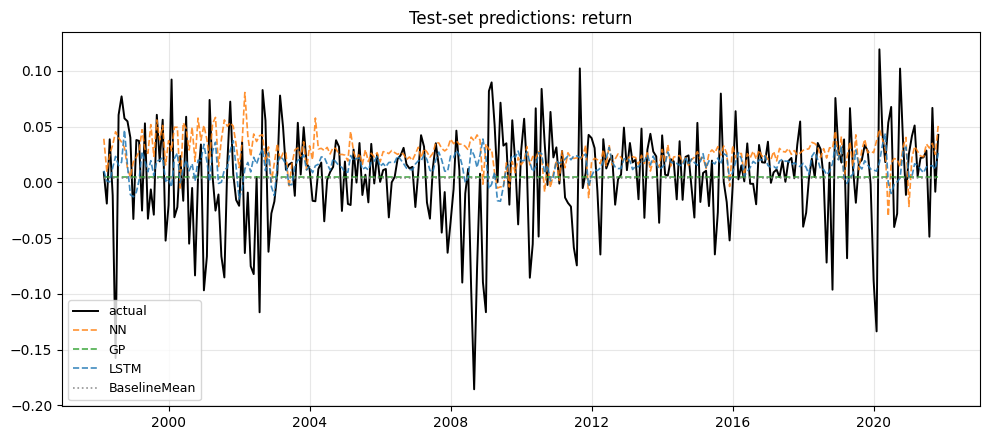

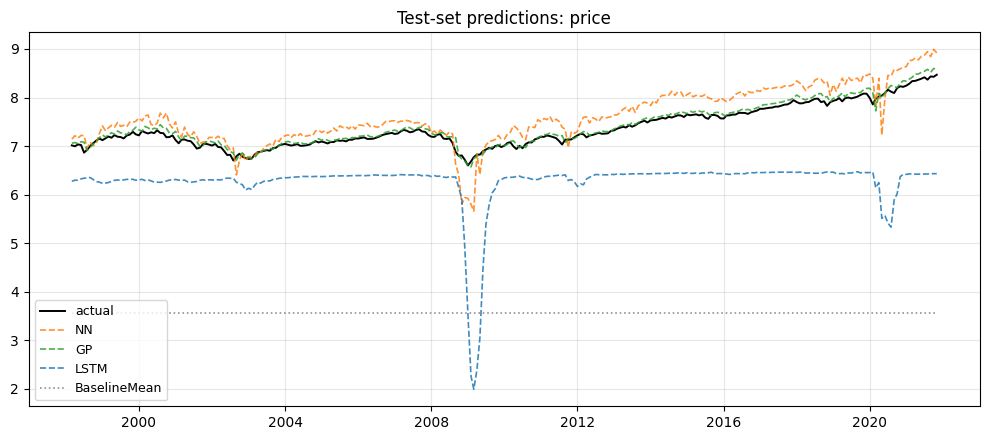

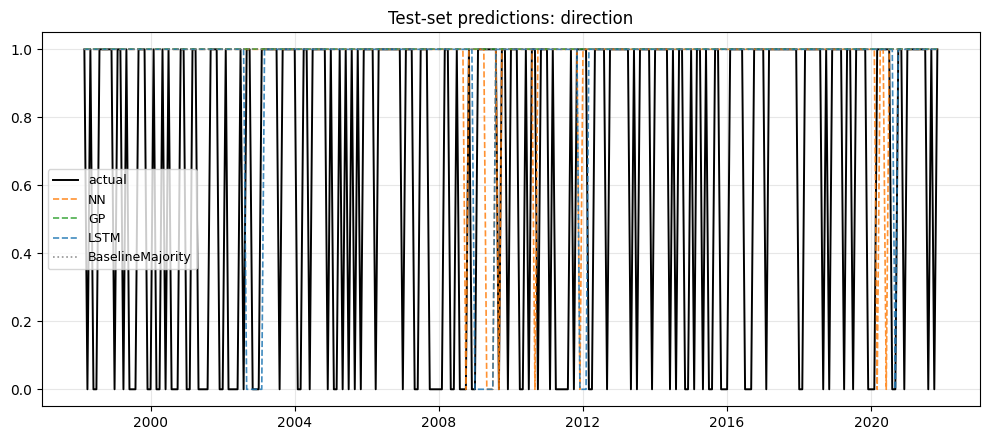

In [14]:
def df_to_latex(df: pd.DataFrame, name: str, caption: str) -> None:
    """Write a DataFrame as a LaTeX table fragment."""
    tex = df.to_latex(
        index=False,
        float_format="{:.4f}".format,
        column_format="l" * len(df.columns),
        escape=False,
    )
    output = (
        "\\begin{table}[H]\n\\centering\n\\small\n"
        + tex
        + "\\caption{"
        + caption
        + "}\n\\label{tab:"
        + name
        + "}\n\\end{table}\n"
    )
    (OUTPUT_DIR / f"{name}.tex").write_text(output)


model_registry = metrics_df[["target", "model", "params"]].copy()
model_registry.to_csv(OUTPUT_DIR / "ex2_model_registry.csv", index=False)
metrics_df.to_csv(OUTPUT_DIR / "ex2_metrics.csv", index=False)
df_to_latex(
    metrics_df,
    "ex2_metrics",
    "Test-set forecast performance for each (target, model) combination.",
)

sens_df.to_csv(OUTPUT_DIR / "ex2_sensitivity.csv", index=False)
df_to_latex(
    sens_df,
    "ex2_sensitivity",
    "Sensitivity analysis: each row is the test-set performance when all lags "
    "of the indicated variable are removed from the feature set.",
)

PRED_FILES = {
    "return": "ex2_pred_return.csv",
    "price": "ex2_pred_price.csv",
    "direction": "ex2_pred_direction.csv",
}
FIG_FILES = {
    "return": "ex2_fig_return.pdf",
    "price": "ex2_fig_price.pdf",
    "direction": "ex2_fig_direction.pdf",
}
STYLE = {
    "NN": ("--", "tab:orange"),
    "GP": ("--", "tab:green"),
    "LSTM": ("--", "tab:blue"),
    "BaselineMean": (":", "grey"),
    "BaselineMajority": (":", "grey"),
}

for target_kind, preds in all_preds.items():
    y_te = all_truths[target_kind]
    output = pd.DataFrame({"y_true": y_te.values}, index=y_te.index)
    for model_name, prediction in preds.items():
        output[f"pred_{model_name}"] = np.asarray(prediction)
    output.to_csv(OUTPUT_DIR / PRED_FILES[target_kind])

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(y_te.index, y_te.values, label="actual", color="black", linewidth=1.4)
    for model_name, prediction in preds.items():
        linestyle, colour = STYLE.get(model_name, ("--", "tab:purple"))
        ax.plot(
            y_te.index,
            np.asarray(prediction),
            label=model_name,
            linestyle=linestyle,
            color=colour,
            alpha=0.85,
            linewidth=1.2,
        )
    ax.set_title(f"Test-set predictions: {target_kind}")
    ax.legend(loc="best", fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / FIG_FILES[target_kind], bbox_inches="tight")
    plt.show()
    plt.close(fig)

feature_selection = pd.DataFrame(
    {target: pd.Series(cols) for target, cols in all_features.items()}
)
feature_selection.to_csv(OUTPUT_DIR / "ex2_feature_selection.csv", index=False)
LOGGER.info("Artifacts written to %s", OUTPUT_DIR)

## Part 10. Where the files go

No archive is bundled here. The script just drops CSV, TeX and figure artefacts into `output/`, which is where the report and the macro-generation script look for them.